<a href="https://colab.research.google.com/github/julia-iza/Trabajo-Practico-Laboratorio/blob/main/analisis_subte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# **Carga de los datos históricos**

Cargamos los archivos procesados de viajes en subte correspondientes a los años 2015 a 2026. El objetivo es reunir información suficiente para estudiar la evolución de la demanda y comparar los patrones de viaje a lo largo del tiempo. El año 2026 puede contener datos parciales, por lo que se analizará teniendo en cuenta su cobertura temporal.

# ***Carga y unificación de los datos***

En esta sección cargamos los archivos procesados de viajes en subte correspondientes a los años 2015–2026 desde el repositorio de GitHub. Convertimos la columna fecha a un formato de fecha y agregamos una columna con el año de cada registro. Luego, unificamos los archivos en un único DataFrame llamado df.

Esta operación permite trabajar con los datos de distintos años en una misma tabla y facilita la comparación de la demanda a lo largo del tiempo, así como la elaboración de visualizaciones para responder la pregunta de investigación.

In [3]:
anios = range(2015, 2027)
bases = []

for anio in anios:
    url = (
        "https://raw.githubusercontent.com/"
        "julia-iza/Trabajo-Practico-Laboratorio/main/"
        f"data/processed/por_anio/molinetes_{anio}.csv.gz"         #tarea asistida por IA, se le pidio la realizacion del codigo para cargar y unificar los archivos procesados de viajes de subte de los años 2015-2026

    )

    try:
        df_anio = pd.read_csv(url, compression="gzip")
        df_anio["fecha"] = pd.to_datetime(df_anio["fecha"])
        df_anio["anio"] = anio

        bases.append(df_anio)
        print(f"{anio}: {len(df_anio):,} filas cargadas")

    except Exception as e:
        print(f"{anio}: no se pudo cargar. Error: {e}")

df = pd.concat(bases, ignore_index=True)

print("\nTotal de filas:", f"{len(df):,}")
print("\nAños cargados:", sorted(df["anio"].unique()))

df.head()


2015: 522,807 filas cargadas
2016: 545,897 filas cargadas
2017: 547,713 filas cargadas
2018: 561,732 filas cargadas
2019: 589,004 filas cargadas
2020: 359,496 filas cargadas
2021: 426,415 filas cargadas
2022: 597,791 filas cargadas
2023: 583,852 filas cargadas
2024: 579,787 filas cargadas
2025: 589,075 filas cargadas
2026: 399,163 filas cargadas

Total de filas: 6,302,732

Años cargados: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio
0,2015-01-01,5,LineaA,PLAZA MISERERE,0,0,0,0,2015
1,2015-01-01,5,LineaD,CATEDRAL,0,0,0,0,2015
2,2015-01-01,5,LineaD,CONGRESO DE TUCUMAN,0,0,0,0,2015
3,2015-01-01,5,LineaH,CASEROS,0,0,0,0,2015
4,2015-01-01,6,LineaC,INDEPENDENCIA,0,0,0,0,2015


In [4]:
df.tail()

,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio
6302727,2026-08-31,23,LineaH,LAS HERAS,13,0,1,14,2026
6302728,2026-08-31,23,LineaH,ONCE,9,0,2,11,2026
6302729,2026-08-31,23,LineaH,PATRICIOS,8,0,1,9,2026
6302730,2026-08-31,23,LineaH,SANTA FE,12,0,5,17,2026
6302731,2026-08-31,23,LineaH,VENEZUELA,11,0,11,22,2026


# ***Exploración inicial de los datos***

Antes de construir las visualizaciones, verificamos que los datos se hayan cargado correctamente. Observamos las primeras filas del DataFrame y comprobamos qué años están disponibles y cuántos registros contiene cada uno. Esto nos permite conocer la estructura de los datos y detectar posibles problemas antes de continuar con el análisis.

In [9]:
print("Dimensiones de la tabla:", df.shape)

print("\nAños disponibles:")
print(sorted(df["anio"].unique()))

print("\nCantidad de registros por año:")
print(df.groupby("anio").size())

print("\nPrimeras filas:")
display(df.head())


Dimensiones de la tabla: (6302732, 9)

Años disponibles:
[np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Cantidad de registros por año:
anio
2015    522807
2016    545897
2017    547713
2018    561732
2019    589004
2020    359496
2021    426415
2022    597791
2023    583852
2024    579787
2025    589075
2026    399163
dtype: int64

Primeras filas:


,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio
0,2015-01-01,5,LineaA,PLAZA MISERERE,0,0,0,0,2015
1,2015-01-01,5,LineaD,CATEDRAL,0,0,0,0,2015
2,2015-01-01,5,LineaD,CONGRESO DE TUCUMAN,0,0,0,0,2015
3,2015-01-01,5,LineaH,CASEROS,0,0,0,0,2015
4,2015-01-01,6,LineaC,INDEPENDENCIA,0,0,0,0,2015


# ***Evolución anual de la cantidad de pasajeros (grafico 1)***

Agrupamos los registros por año y sumamos la variable total, que representa la cantidad de pasajeros registrada en cada observación. Luego, construimos un gráfico de líneas para visualizar la evolución de los viajes entre 2015 y 2026 e identificar tendencias, caídas y posibles recuperaciones de la demanda. El año 2026 debe interpretarse con cautela porque contiene datos parciales.

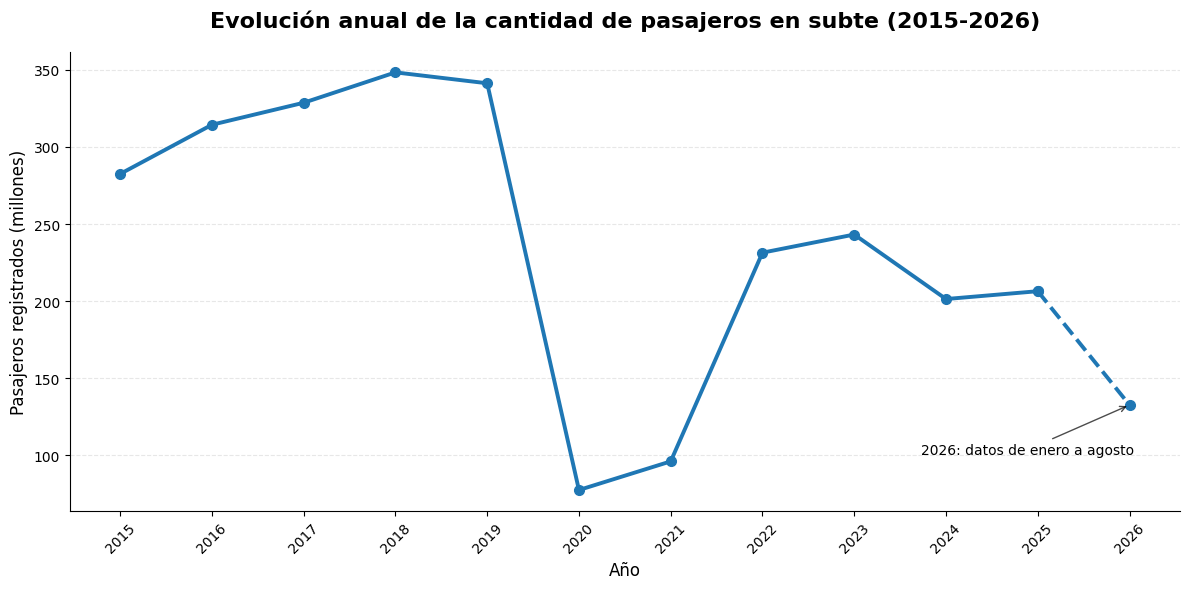

In [17]:
# Sumamos los pasajeros registrados en cada año (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

anual = df_sub.groupby("anio")["total"].sum() / 1_000_000
                                                                #tarea asistida por IA se le pidio la realizacion de un grafico de lineas sobre la evolucion anual de la cantidad de pasajeros en subte, remarcando el año 2026 con lineas puntiagudas y una aclaracion sobre que es de enero hasta agosto
# Creamos el gráfico
plt.figure(figsize=(12, 6))

# Años completos (línea continua)
plt.plot(
    anual.index[:-1],
    anual.values[:-1],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#1f77b4"
)

# Último tramo, con 2026 parcial (línea punteada)
plt.plot(
    anual.index[-2:],
    anual.values[-2:],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#1f77b4",
    linestyle="--"
)

# Título y nombres de los ejes
plt.title(
    "Evolución anual de la cantidad de pasajeros en subte (2015-2026)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Año", fontsize=12)
plt.ylabel("Pasajeros registrados (millones)", fontsize=12)

# Mostramos todos los años en el eje horizontal
plt.xticks(anual.index, rotation=45)

# Agregamos una cuadrícula suave
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Quitamos los bordes superior y derecho
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Aclaración sobre 2026
plt.annotate(
    "2026: datos de enero a agosto",
    xy=(2026, anual.loc[2026]),
    xytext=(-150, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", alpha=0.7),
    fontsize=10
)

plt.tight_layout()

# Guardamos la imagen
plt.savefig("figuras_evolucion_anual.png", dpi=300, bbox_inches="tight")

plt.show()



### ***Interpretación del gráfico***

La serie muestra tres etapas bien diferenciadas. Entre 2015 y 2018, la cantidad de pasajeros registrados creció de forma sostenida, de unos 283 a unos 348 millones, y en 2019 se mantuvo en un nivel similar (alrededor de 341 millones). En 2020 se observa la caída más pronunciada de toda la serie, a unos 78 millones de pasajeros (cerca de un 77 % menos que en 2019), que coincide con las restricciones a la circulación por la pandemia de COVID-19. En 2021 la recuperación es leve y en 2022 hay un salto fuerte hasta unos 231 millones, que continúa en 2023 (unos 243 millones).

Sin embargo, la demanda no volvió al nivel previo a la pandemia. Incluso en su mejor año posterior (2023), el subte registró alrededor de un 70 % de los pasajeros de 2019. Además, en 2024 se produce una nueva baja (a unos 201 millones) y en 2025 el valor se mantiene en un nivel similar (unos 207 millones), alrededor de un 40 % por debajo del máximo de 2018. El valor de 2026 es menor porque solo incluye datos de enero a agosto, por lo que no es comparable con los años completos y no indica por sí solo una nueva caída. Por eso se dibuja con línea punteada.

En conjunto, la evidencia sugiere una **recuperación parcial, pero no total**, de la demanda previa a la pandemia.

**Posibles explicaciones.** Los datos muestran qué ocurrió, pero no por qué. Distintos informes (por ejemplo, del Observatorio de Tarifas y Subsidios del IIEP, UBA-CONICET) atribuyen la baja demanda al avance del teletrabajo y a los aumentos de tarifa del subte desde mayo de 2024, que ampliaron la diferencia de precio con el colectivo. Estas explicaciones deben tomarse como hipótesis: con este dataset no es posible medir cuánto aporta cada factor.

**Limitaciones a tener en cuenta:**
- Se excluyó la línea Premetro (PM), que aparece en los datos recién desde junio de 2025, para que los años sean comparables.
- Las variables cuentan ingresos por los molinetes, no personas distintas.
- Desde diciembre de 2024 los archivos incluyen otros modos de pago (tarjetas y celular), por lo que podría haber un cambio en lo que se cuenta; la comparación de 2025 y 2026 con años anteriores debe interpretarse con cautela.
- Las fechas de 2020 y 2021 fueron corregidas por inferencia en la limpieza de los datos, por lo que el detalle mensual de esos años es menos confiable (los totales anuales no se ven afectados de forma relevante).

#***comparación de la cantidad de pasajeros por línea  (grafico 2)***

En esta sección agrupamos los registros por línea de subte y sumamos la variable total para calcular la cantidad de pasajeros registrada en cada una durante el período 2015–2026. Luego, representamos los resultados mediante un gráfico de barras para comparar la demanda entre las distintas líneas e identificar cuáles concentran más viajes.

Como el análisis incluye varios años, los resultados representan el acumulado de todo el período y no la demanda actual de cada línea.

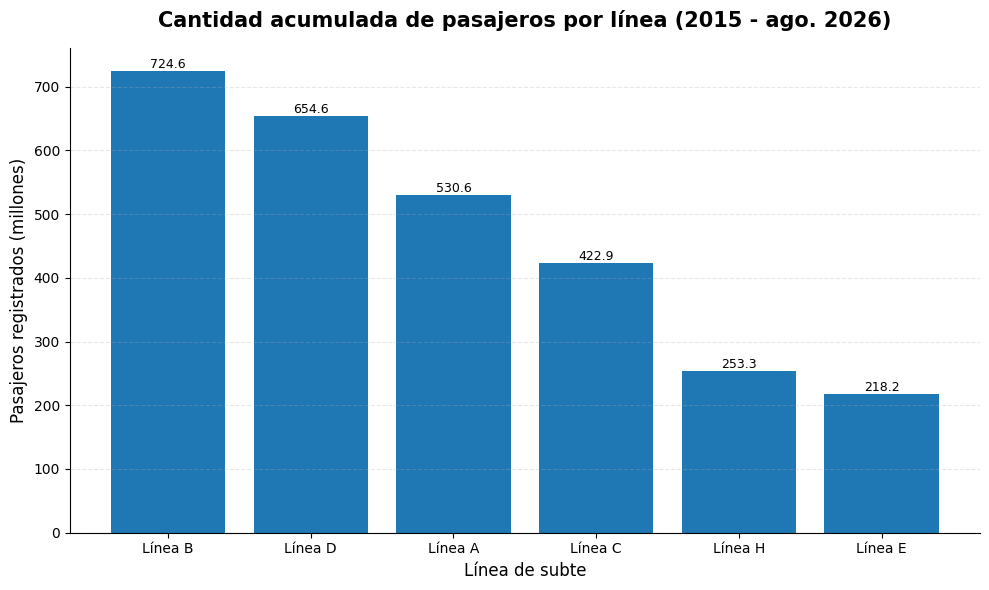

In [20]:
#sumamos los pasajeros registrados en cada linea
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]

por_linea = (
    df[df["linea"].isin(lineas)]
    .groupby("linea")["total"].sum() / 1_000_000               #tarea asitida por IA, se le pidio la realizacion de un grafico de barras sobre la cantida de pasajeros de cada linea en (2015-2026)
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
barras = plt.bar(por_linea.index.str.replace("Linea", "Línea "), por_linea.values)

# Valores sobre las barras
for barra, valor in zip(barras, por_linea.values):
    plt.text(barra.get_x() + barra.get_width() / 2, valor,
             f"{valor:,.1f}", ha="center", va="bottom", fontsize=9)

plt.title("Cantidad acumulada de pasajeros por línea (2015 - ago. 2026)",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Línea de subte", fontsize=12)
plt.ylabel("Pasajeros registrados (millones)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.3)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figuras_pasajeros_por_linea.png", dpi=300, bbox_inches="tight")
plt.show()

## ***Interpretación del gráfico***

El gráfico muestra cuántos ingresos por los molinetes acumuló cada línea entre 2015 y agosto de 2026. La distribución es muy desigual: la línea B (unos 725 millones) y la línea D (unos 655 millones) concentran, entre las dos, cerca de la mitad de todos los ingresos registrados (alrededor del 49 % de un total de unos 2.804 millones). Les siguen la línea A (unos 531 millones, cerca del 19 %) y la línea C (unos 423 millones, cerca del 15 %). Las líneas H y E son las de menor volumen (unos 253 y 218 millones), y juntas representan alrededor del 17 % del total.

En el contexto del dataset, esto significa que la demanda del subte está muy concentrada en pocas líneas. Si el sistema perdió pasajeros después de la pandemia, como se vio en el gráfico anterior, esa pérdida impacta sobre todo en las líneas que más gente mueven. Este resultado aporta a la segunda parte de la pregunta del trabajo (dónde se viaja).

**Cómo leer este gráfico:**
- Los valores son **acumulados** de todo el período, que incluye los años de pandemia y 2026 solo hasta agosto. Sirven para ver qué líneas concentran más ingresos, no para comparar su crecimiento o evolución.
- Una línea con más ingresos no es necesariamente la de "mejor desempeño": las líneas difieren en longitud, cantidad de estaciones y zonas que conectan, y algunas se ampliaron durante el período. Esto puede explicar parte de las diferencias, pero con este dataset no se puede medir.
- Se excluyó el Premetro (PM) porque aparece en los datos recién desde junio de 2025 y no es comparable con las líneas A, B, C, D, E y H.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

#***Distribución de los viajes según la hora del día (gráfico 3)***

En esta sección analizamos la relación entre la hora del día y la cantidad de pasajeros registrados. Para ello, calculamos la cantidad promedio de pasajeros por hora y representamos los resultados mediante un gráfico de dispersión. Esta visualización permite observar cómo varía la demanda según el horario e identificar posibles patrones de uso del subte.

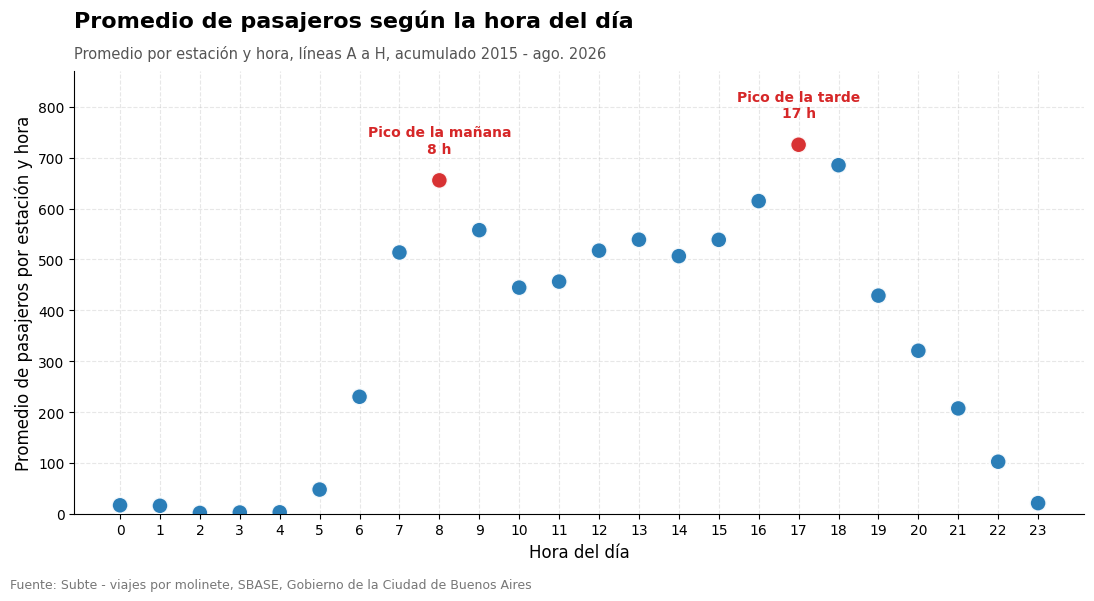

In [28]:
import matplotlib.pyplot as plt

# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

# Promedio de pasajeros por estación y hora, para cada hora del día
pasajeros_hora = df_sub.groupby("hora")["total"].mean()
horas = pasajeros_hora.index
valores = pasajeros_hora.values

# Pico de la mañana y de la tarde (se calculan solos)
pico_manana = pasajeros_hora.loc[5:12].idxmax()
pico_tarde = pasajeros_hora.loc[13:23].idxmax()

azul = "#1f77b4"
rojo = "#d62728"
colores = [rojo if h in (pico_manana, pico_tarde) else azul for h in horas]

fig, ax = plt.subplots(figsize=(11, 6))

# Gráfico de dispersión
ax.scatter(
    horas, valores,
    s=150, c=colores,
    edgecolors="white", linewidths=1.8,
    alpha=0.95, zorder=3
)

# Anotación de los picos
for h, nombre in [(pico_manana, "Pico de la mañana"), (pico_tarde, "Pico de la tarde")]:
    ax.annotate(
        f"{nombre}\n{h} h",
        xy=(h, pasajeros_hora.loc[h]),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=rojo
    )

# Título, subtítulo y ejes
ax.set_title(
    "Promedio de pasajeros según la hora del día",
    fontsize=16, fontweight="bold", loc="left", pad=32
)
ax.text(
    0, 1.03,
    "Promedio por estación y hora, líneas A a H, acumulado 2015 - ago. 2026",
    transform=ax.transAxes, fontsize=10.5, color="#555555"
)

ax.set_xlabel("Hora del día", fontsize=12)
ax.set_ylabel("Promedio de pasajeros por estación y hora", fontsize=12)

ax.set_xticks(range(0, 24))
ax.set_ylim(0, valores.max() * 1.2)
ax.grid(linestyle="--", alpha=0.3, zorder=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Fuente al pie
fig.text(
    0.01, 0.01,
    "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
    fontsize=9, color="#777777"
)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_hora_pasajeros.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación del gráfico

El gráfico muestra un patrón de dos picos bien marcados: uno a las 8 h (unos 656 pasajeros en promedio por estación y hora) y otro, más alto, a las 17 h (unos 726). Entre ambos, la demanda baja pero se mantiene en un nivel alto durante el mediodía y las primeras horas de la tarde: de las 12 a las 15 h el promedio ronda entre 507 y 539 pasajeros, cerca del 70-75 % del pico de la tarde. Entre las 2 y las 4 h los valores son prácticamente nulos y desde las 18 h descienden de forma sostenida hasta la noche.

En el contexto del dataset, esto es el patrón típico de un sistema de transporte usado sobre todo para ir y volver del trabajo y del estudio. El pico de la mañana corresponde a los ingresos de quienes viajan hacia sus destinos y el de la tarde a quienes regresan. Que el segundo sea más alto podría deberse a que la vuelta se reparte en más horarios y motivos (compras, trámites, actividades de la tarde), aunque con estos datos no se puede comprobar. Los valores casi nulos de la madrugada son esperables porque el servicio no funciona en esas horas. Al mismo tiempo, que el mediodía no sea un valle profundo indica que el subte tiene una demanda importante durante todo el día y no solo en las horas pico. Para la pregunta del trabajo, esto significa que la demanda depende mucho de los horarios laborales, por lo que cambios como el teletrabajo podrían afectar sobre todo a las horas pico.

**Cómo leer este gráfico:**
- Los valores son **promedios de todo el período** (2015 a agosto de 2026), que incluye la pandemia, fines de semana y feriados. Mezclar días hábiles con fines de semana suaviza los picos, así que el patrón real de lunes a viernes es probablemente más marcado.
- Al promediar todos los años no permite ver si el patrón **cambió** después de la pandemia. Para eso habría que comparar, por ejemplo, 2019 con 2024-2025.
- Cada estación se cuenta una vez por línea, por lo que las estaciones de combinación aparecen en cada una de sus líneas.
- Se excluyó el Premetro (PM) porque aparece en los datos recién desde junio de 2025 y no es comparable con las líneas A, B, C, D, E y H.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

# ***Cambios en la hora en que se viaja: 2019 vs. 2024-2025 (gráfico 4)***

**Qué se busca y qué se hizo.** Este gráfico busca responder si cambió *cuándo* se viaja en subte después de la pandemia. Para eso se compara 2019 (último año completo previo a la pandemia) con 2024-2025 (los años completos más recientes) usando las líneas A, B, C, D, E y H. Como el total de pasajeros cayó entre ambas épocas, no se comparan cantidades sino el **porcentaje de los pasajeros de cada período que viaja en cada hora**, lo que permite ver si cambió la forma del día y no solo su nivel. Se representa con un gráfico de dispersión, con un color por período.

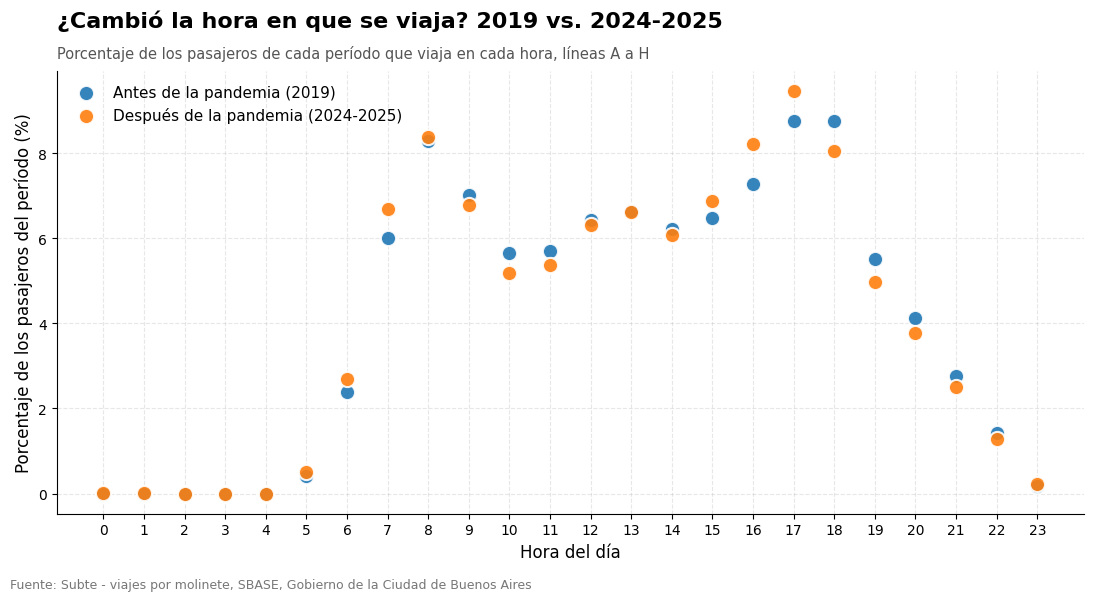

In [36]:


# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

# Períodos a comparar
antes = df_sub[df_sub["anio"] == 2019]
despues = df_sub[df_sub["anio"].isin([2024, 2025])]

# Porcentaje de los pasajeros del período que viaja en cada hora
def perfil_horario(d):
    return d.groupby("hora")["total"].sum() / d["total"].sum() * 100

p_antes = perfil_horario(antes)
p_despues = perfil_horario(despues)

azul = "#1f77b4"
naranja = "#ff7f0e"

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(p_antes.index, p_antes.values, s=120, color=azul,
           edgecolors="white", linewidths=1.5, alpha=0.9,
           label="Antes de la pandemia (2019)", zorder=3)
ax.scatter(p_despues.index, p_despues.values, s=120, color=naranja,
           edgecolors="white", linewidths=1.5, alpha=0.9,
           label="Después de la pandemia (2024-2025)", zorder=3)

ax.set_title("¿Cambió la hora en que se viaja? 2019 vs. 2024-2025",
             fontsize=16, fontweight="bold", loc="left", pad=32)
ax.text(0, 1.03,
        "Porcentaje de los pasajeros de cada período que viaja en cada hora, líneas A a H",
        transform=ax.transAxes, fontsize=10.5, color="#555555")

ax.set_xlabel("Hora del día", fontsize=12)
ax.set_ylabel("Porcentaje de los pasajeros del período (%)", fontsize=12)

ax.set_xticks(range(0, 24))
ax.grid(linestyle="--", alpha=0.3, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=11)

fig.text(0.01, 0.01,
         "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
         fontsize=9, color="#777777")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_hora_antes_despues.png", dpi=300, bbox_inches="tight")
plt.show()



### ***Interpretación del gráfico***

Las dos curvas son muy parecidas: en ambos períodos hay un pico a las 8 h, una meseta al mediodía y un segundo pico, el más alto, a las 17 h. Esto indica que la **distribución horaria de la demanda cambió poco** entre 2019 y 2024-2025: ninguna hora varió su participación en más de 1 punto porcentual.

Dentro de esa estabilidad hay un corrimiento pequeño pero consistente. Ganaron peso las primeras horas de la mañana (las 6 y 7 h, +0,3 y +0,7 puntos) y el tramo de 15 a 17 h (+0,4, +1,0 y +0,7 puntos). Perdieron peso el mediodía (de 9 a 12 h, hasta -0,5 puntos) y, sobre todo, el tramo de 18 a 22 h (entre -0,1 y -0,7 puntos). Como el total de pasajeros cayó entre ambas épocas, esto significa que las horas pico de entrada y de regreso retuvieron mejor su demanda que el resto del día. Una explicación posible es que los viajes por trabajo o estudio se mantuvieron más que los viajes de mediodía y de la noche, y que el regreso se concentra un poco más temprano, pero con estos datos no se puede comprobar.

En el contexto de la pregunta del trabajo, el resultado es que el subte **no recuperó el nivel de pasajeros previo a la pandemia, pero el patrón horario de uso se mantuvo casi igual**: se viaja principalmente en las mismas horas, aunque con menos pasajeros en total y con un poco más de peso de las horas pico de la tarde.

**Cómo leer este gráfico:**
- Muestra **proporciones**, no cantidades: que una hora tenga un porcentaje parecido no significa que tenga la misma cantidad de pasajeros, ya que el total de 2024-2025 es menor. Una hora que "gana peso" puede haber perdido pasajeros, pero menos que el resto.
- No separa días hábiles de fines de semana, por lo que los picos aparecen suavizados.
- Desde diciembre de 2024 el dataset podría incluir otros medios de pago, por lo que 2025 es el año con mayor incertidumbre.
- Se excluyó el Premetro (PM), que aparece en los datos recién desde junio de 2025.
- Las variables cuentan ingresos por los molinetes, no personas distintas.